The third lattice example featuring more complicated fill


In [1]:
import openmc as omc
import numpy as np

# Material definitions
materials=omc.Materials()

m1 = omc.Material()
m1.add_nuclide('Be9', 1.0)
m1.set_density('g/cc',0.6)
materials.append(m1)

m2 = omc.Material()
m2.add_element('C',1.0)
m2.set_density('g/cc',0.8)

materials.append(m2)
m3 = omc.Material()
m3.add_nuclide('Al27',1.0)
m3.set_density('g/cc',2.7)
materials.append(m3)
materials.export_to_xml()

In [2]:
# Surface definitions
s1 = omc.Sphere(r=3,y0=-5)
s2 = omc.YPlane(0)
s3 = omc.ZPlane(0)
s4 = omc.Sphere(r=15,boundary_type = 'vacuum')
s5 = omc.XPlane(1.5)
s6 = omc.XPlane(-1.5)
s7 = omc.YPlane(1)
s8 = omc.YPlane(-1)
s9 = omc.ZPlane(3)
s10 = omc.ZPlane(-3)
s11 = omc.Plane(1,-0.5,0,1.3)
s12 = omc.Plane(1,-0.5,0,-1.3)
s13 = omc.YPlane(0.5)
s14 = omc.YPlane(-0.5)
s15 = omc.ZPlane(3)
s16 = omc.ZPlane(-3)
s17 = omc.Quadric(a=1, b=2, g=-0.4, k= -0.6) # (x - 0.2)^2 + 2 y^2 = 1
s18 = omc.Sphere(r=10)

In [3]:
# Universe definitions
# One reason to put universe creation into functions is to make all universe definitions available
# at script runtime. 
def fill_u1():
    c6 = omc.Cell(fill=fill_u3(),region=(-s5&+s6&-s7&+s8&-s9&+s10))
    u1 = omc.Universe(cells=[c6])
    return u1

def fill_u2():
    c7 = omc.Cell(fill=fill_u5(),region=(-s11 & +s12 & -s13 & +s14 & -s15 & +s16))
    u2 = omc.Universe(cells=[c7])
    return u2

def fill_u3():
    c8 = omc.Cell(fill=m2,region=-s17)
    c9 = omc.Cell(fill=None,region=+s17)
    u3 = omc.Universe(cells=[c8,c9])
    return u3

def fill_u4():
    c10 = omc.Cell(fill=None,region=-s18)
    u4 = omc.Universe(cells=[c10])
    return u4
u4 = fill_u4()

def fill_u5():
    c18 = omc.Cell(fill=m3, region=-s18)
    u5 = omc.Universe(cells=[c18])
    return u5

c1 = omc.Cell(fill=m1,region=-s1)
c2 = omc.Cell(fill=fill_u1(),region=+s1&-s2&-s4)
c3 = omc.Cell(fill=fill_u2(),region=+s2&-s3&-s4)
c3.translation = (-7,5,0)
c3.rotation=((30,60,90),(120,30,90),(90,90,0))

c4 = omc.Cell(fill=fill_u2(),region=+s2&+s3&-s4)
c4.translation = (4, 8, 0)
c4.rotation = ((15, 105, 90), (75, 15, 90), (90, 90, 0))

c5 = omc.Cell(fill=None,region=+s4)


#u_root = omc.Universe([

geometry=omc.Geometry([c1,c2,c3,c4,c5])

model = omc.model.Model()
model.geometry=geometry
model.materials=materials

settings=omc.Settings()
model.settings=settings
geometry.export_to_xml()
settings.export_to_xml()

In [4]:
w = 45
plots = omc.Plots()

plot = omc.SlicePlot()
plot.basis = 'xy'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level=level
plots.append(plot)

plot = omc.SlicePlot()
plot.basis = 'xz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level=level
plots.append(plot)

plot = omc.SlicePlot()
plot.basis = 'yz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'
#plot.level = level
plots.append(plot)

model.plots=plots
#model.export_to_xml()

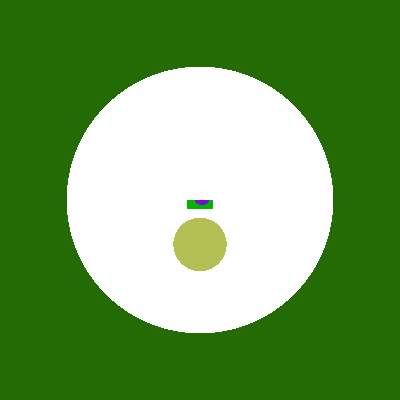

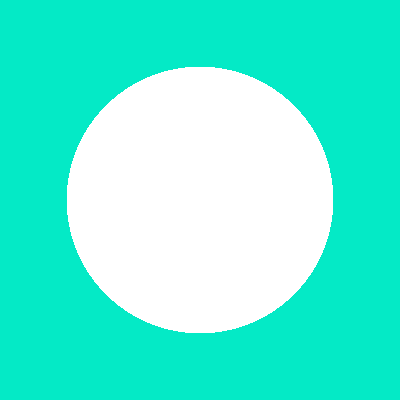

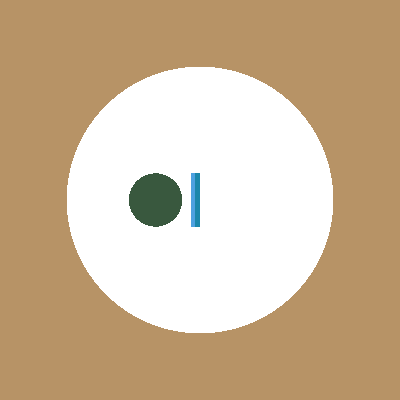

In [5]:
omc.plot_inline(plots)